# 07. Модель для текущего рынка: обучение на 2024–2026, проверка на самых новых вакансиях

Модели 01–06 обучены на вакансиях февраля–марта 2024. Анализ динамики (репозиторий kg-job-market-analysis,
ноутбук 08) показал, что та же вакансия с тех пор подорожала примерно на 31%. Значит, модель 2024 года
для сегодняшних вакансий будет **занижать** зарплату.

**Данные:** `vacancies_2024_2026.csv` (hh, lalafo, Telegram-каналы codifynews и kgworkzone, январь 2024 – октябрь 2026).

**Честная проверка во времени:** модель учится только на прошлом и проверяется на будущем.

| Часть | Период | Зачем |
|---|---|---|
| обучение | январь 2024 – июнь 2026 | подбор весов |
| калибровка | апрель–июнь 2026 (последний квартал обучения) | ширина диапазонов |
| **тест** | **июль – октябрь 2026** | ошибка на вакансиях, которых модель не видела, из «будущего» |

**Повторы:**
- одна и та же вакансия (тот же заголовок, работодатель или начало текста, и зарплата), опубликованная снова в течение 30 дней,
  считается **повтором** и удаляется (остаётся первая публикация);
- из теста удаляются вакансии, у которых **тот же заголовок и тот же работодатель** (или тот же текст) уже были в обучении:
  иначе модель «узнавала» бы ответ по повторному объявлению.

**Сравниваются:**
- **A.** финальная модель 2024 года (`final_model.joblib`) как есть, без переобучения;
- **B.** та же модель, переобученная на всех данных 2024–2026, без признака времени;
- **C.** B + признак времени (номер месяца публикации);
- **D.** C + работодатель (`company`);
- **E.** D, но только на вакансиях с 2025 года;
- **F.** D + **уровень** (junior / middle / senior / lead: из заголовка, а если его там нет, из требуемого опыта)
  и сочетания «сфера × опыт», «сфера × уровень»: опыт может стоить по-разному в IT и в торговле;
- базовые уровни: медиана рынка и медиана профессии за последние 6 месяцев обучения.

In [1]:
import sys, json, time
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import seaborn as sns
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
import prep

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
K = mt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")

df = prep.load("../data/vacancies_2024_2026.csv")
df["published"] = pd.to_datetime(df["published"])
df = df[df["published"] >= "2024-01-01"].copy()
df["company"] = df["company"].fillna("не указано").astype(str).str.lower().str.strip()
df["experience_known"] = df["experience_known"].fillna(True).astype(int)
# месяц публикации: 0 = январь 2024
df["month_n"] = (df["published"].dt.year - 2024) * 12 + df["published"].dt.month - 1
df = prep.add_level(df)     # уровень (junior…lead) из заголовка или из опыта; сфера×опыт

# шумные метки: как в prep.labeled, но фильтр 5x применяется ко всем источникам со свободным текстом
d = df[df["has_salary"]].copy()
ratio = d["salary_kgs"] / d.groupby("sub_category")["salary_kgs"].transform("median")
noise = ((ratio > 5) | (ratio < 0.2)) & d["source"].isin(["lalafo", "telegram_kgworkzone"])
d = d[~noise].copy()
d["y"] = np.log(d["salary_kgs"])

# повторные публикации: тот же заголовок + работодатель + зарплата в течение 30 дней
norm = lambda s: s.fillna("").str.lower().str.replace(r"[^а-яёa-z0-9]+", " ", regex=True).str.strip()
# где работодатель не указан (lalafo, kgworkzone), вместо него берётся начало текста объявления
d["vac_key"] = (norm(d["name"]) + "|" + norm(d["company"].replace("не указано", "")) + "|"
                + norm(d["requirements"]).str.slice(0, 100))
d = d.sort_values("published")
gap = d.groupby([d["vac_key"], d["salary_kgs"].round(-2)])["published"].diff()
repost = gap <= pd.Timedelta(days=30)
n_all = len(d)
d = d[~repost].reset_index(drop=True)
print(f"Вакансий с зарплатой: {n_all} | шум: {noise.sum()} | повторы за 30 дней: {repost.sum()} | осталось: {len(d)}")
print("Уникальных по годам:", d["published"].dt.year.value_counts().sort_index().to_dict())

TEST_FROM, CAL_FROM = pd.Timestamp("2026-07-01"), pd.Timestamp("2026-04-01")
train = d[d["published"] < TEST_FROM].reset_index(drop=True)
test = d[d["published"] >= TEST_FROM]
n0 = len(test)
test = test[~test["vac_key"].isin(set(train["vac_key"]))].reset_index(drop=True)
print(f"Обучение: {len(train)} | тест: {len(test)} (убрано повторов из обучения: {n0 - len(test)})")
pd.crosstab(test["source"], test["published"].dt.to_period("M"))

/home/claude/kg-salary-prediction/notebooks/../src/prep.py:41: DtypeWarning: Columns (0: skills, 1: requirements, 2: responsibilities) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


Вакансий с зарплатой: 22681 | шум: 29 | повторы за 30 дней: 118 | осталось: 22563
Уникальных по годам: {2024: 9805, 2025: 6627, 2026: 6131}
Обучение: 20389 | тест: 1784 (убрано повторов из обучения: 390)


published,2026-07,2026-08,2026-09,2026-10
source,,,,
telegram_codifynews,372,329,379,324
telegram_kgworkzone,141,82,108,49


## Модели

In [2]:
P = json.load(open("../models/final_model_meta.json"))["params"]
C, N, B = prep.CAT_FEATURES, prep.NUM_FEATURES, prep.BOOL_FEATURES + ["experience_known"]

def build(cat, num, p=P):
    ct = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=p["min_freq"]), cat),
        ("num", StandardScaler(), num),
        ("t", TfidfVectorizer(min_df=p["min_df"], sublinear_tf=True, ngram_range=(1, p["word_ngram"]),
                              max_features=p["word_max"]), "full"),
        ("ti", TfidfVectorizer(min_df=p["min_df"], sublinear_tf=True, analyzer="char_wb",
                               ngram_range=(2, p["char_max"])), "title"),
    ], transformer_weights={"ti": p["title_weight"]})
    return make_pipeline(ct, Ridge(alpha=p["alpha"]))

VARIANTS = {
    "B. 2024–2026, без времени":        (C, N + B, None),
    "C. + месяц публикации":            (C, N + B + ["month_n"], None),
    "D. + работодатель":                (C + ["company"], N + B + ["month_n"], None),
    "E. как D, только 2025–2026":       (C + ["company"], N + B + ["month_n"], "2025-01-01"),
    "F. D + уровень, сфера×опыт":       (C + ["company", "level", "cat_exp", "cat_level"], N + B + ["month_n"], None),
}

rows, preds, fitted = [], {}, {}
def score(name, p_log, n_train):
    m = prep.metrics(test["y"].values, p_log)
    rows.append({"модель": name, "обучение, вакансий": n_train, **m,
                 "смещение, %": (np.exp(p_log) / test["salary_kgs"] - 1).median() * 100})
    preds[name] = p_log

# базовые уровни: медианы последних 6 месяцев обучения
last = train[train["published"] >= TEST_FROM - pd.DateOffset(months=6)]
score("медиана рынка (посл. 6 мес.)", np.full(len(test), last["y"].median()), len(last))
prof = last.groupby("sub_category")["y"].median()
score("медиана профессии (посл. 6 мес.)", test["sub_category"].map(prof).fillna(last["y"].median()).values, len(last))

# A: модель 2024 без переобучения
old = joblib.load("../models/final_model.joblib")
score("A. модель 2024 без переобучения", old.predict(test), 5820)

for name, (cat, num, since) in VARIANTS.items():
    tr = train if since is None else train[train["published"] >= since]
    t0 = time.time()
    m = build(cat, num).fit(tr, tr["y"])
    fitted[name] = (m, cat, num, since)
    score(name, m.predict(test), len(tr))
    print(f"{name}: {time.time() - t0:.0f} c")

res = pd.DataFrame(rows).set_index("модель")
res.style.format({"обучение, вакансий": "{:,.0f}", "MAE, сом": "{:,.0f}", "медианная ошибка, сом": "{:,.0f}",
                  "MAPE, %": "{:.1f}", "доля ошибок < 20%": "{:.0%}", "R² (log)": "{:.3f}", "смещение, %": "{:+.1f}"}
                 ).highlight_min(subset=["MAE, сом"], color="#cde8cd")

B. 2024–2026, без времени: 3 c


C. + месяц публикации: 3 c


D. + работодатель: 4 c


E. как D, только 2025–2026: 2 c


F. D + уровень, сфера×опыт: 4 c


,"обучение, вакансий","MAE, сом","медианная ошибка, сом","MAPE, %",доля ошибок < 20%,R² (log),"смещение, %"
модель,,,,,,,
медиана рынка (посл. 6 мес.),"3,957","34,365","20,000",41.5,26%,-0.052,-7.7
медиана профессии (посл. 6 мес.),"3,957","30,886","20,000",39.8,35%,0.136,-4.0
A. модель 2024 без переобучения,"5,820","39,072","24,666",41.0,23%,-0.585,-35.6
"B. 2024–2026, без времени","20,389","27,780","17,520",34.2,37%,0.306,-8.1
C. + месяц публикации,"20,389","27,616","17,068",36.6,38%,0.338,-0.3
D. + работодатель,"20,389","26,634","16,532",35.4,40%,0.372,+1.2
"E. как D, только 2025–2026","10,584","26,673","16,755",36.2,41%,0.349,+2.0
"F. D + уровень, сфера×опыт","20,389","26,693","16,543",35.2,41%,0.374,+1.1


**Как читать:** «смещение» это медиана (прогноз / факт − 1). Отрицательное смещение значит, что модель
систематически занижает зарплату.

Минимальная MAE: D. + работодатель (26,634) | выбрана: F. D + уровень, сфера×опыт (26,693)


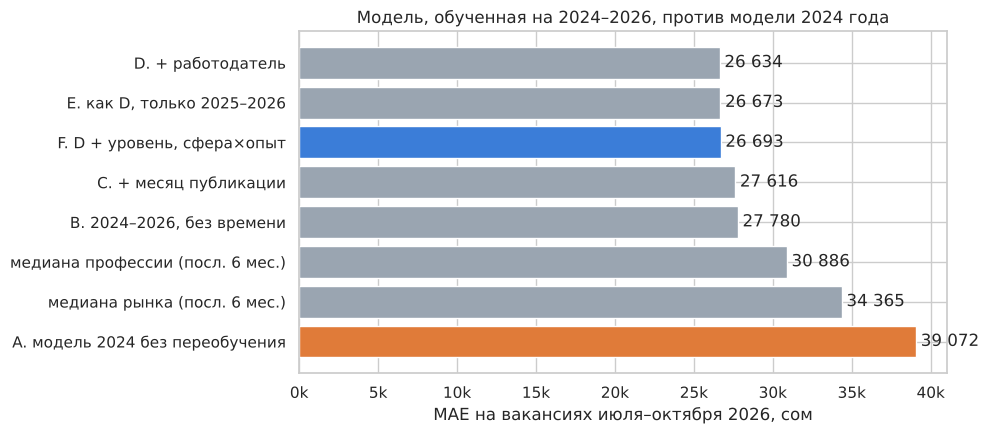

In [3]:
models_only = res.drop(index=[i for i in res.index if i.startswith("медиана")])
best_mae = models_only["MAE, сом"].min()
# правило выбора: при разнице в MAE меньше 1% выбирается F, у неё осмысленнее влияние опыта (раздел ниже)
best = "F. D + уровень, сфера×опыт" if models_only.loc["F. D + уровень, сфера×опыт", "MAE, сом"] <= best_mae * 1.01        else models_only["MAE, сом"].idxmin()
print(f"Минимальная MAE: {models_only['MAE, сом'].idxmin()} ({best_mae:,.0f}) | выбрана: {best} ({res.loc[best, 'MAE, сом']:,.0f})")
fig, ax = plt.subplots(figsize=(10, 4.5))
order = res.sort_values("MAE, сом").index
cols = ["#3b7dd8" if i == best else "#e07b39" if i.startswith("A.") else "#9aa5b1" for i in order]
ax.barh(order[::-1], res.loc[order[::-1], "MAE, сом"], color=cols[::-1])
for i, v in enumerate(res.loc[order[::-1], "MAE, сом"]):
    ax.text(v + 300, i, f"{v:,.0f}".replace(",", " "), va="center")
ax.xaxis.set_major_formatter(K); ax.set_xlabel("MAE на вакансиях июля–октября 2026, сом")
ax.set_title("Модель, обученная на 2024–2026, против модели 2024 года")
plt.tight_layout(); plt.savefig(FIG + "07_time_models.png", dpi=150); plt.show()

## Ошибка по источникам и уровням зарплаты (лучшая модель против модели 2024)

In [4]:
t = test.assign(best=np.exp(preds[best]), old=np.exp(preds["A. модель 2024 без переобучения"]))
t["band"] = pd.cut(t["salary_kgs"], [0, 25e3, 40e3, 60e3, 100e3, 1e9], labels=["<25k", "25–40k", "40–60k", "60–100k", "100k+"])
def seg(g):
    return pd.Series({"вакансий": len(g), "медиана зарплаты": g["salary_kgs"].median(),
                      "MAE модель 2024": (g["old"] - g["salary_kgs"]).abs().mean(),
                      "MAE новая модель": (g["best"] - g["salary_kgs"]).abs().mean(),
                      "медианная ошибка новой": (g["best"] - g["salary_kgs"]).abs().median(),
                      "смещение 2024, %": (g["old"] / g["salary_kgs"] - 1).median() * 100,
                      "смещение новой, %": (g["best"] / g["salary_kgs"] - 1).median() * 100})
tab = pd.concat([t.groupby("source").apply(seg), t.groupby("band", observed=True).apply(seg), seg(t).to_frame("весь тест").T])
tab.style.format({"вакансий": "{:.0f}", "медиана зарплаты": "{:,.0f}", "MAE модель 2024": "{:,.0f}", "MAE новая модель": "{:,.0f}",
                  "медианная ошибка новой": "{:,.0f}", "смещение 2024, %": "{:+.0f}", "смещение новой, %": "{:+.0f}"})

,вакансий,медиана зарплаты,MAE модель 2024,MAE новая модель,медианная ошибка новой,"смещение 2024, %","смещение новой, %"
telegram_codifynews,1404,"70,000","44,538","28,946","17,732",-41,-0
telegram_kgworkzone,380,"50,000","18,877","18,371","13,820",-18,+7
<25k,54,"21,214","19,073","27,000","26,345",+67,+134
25–40k,272,"37,500","7,420","18,619","15,574",+6,+42
40–60k,495,"50,000","14,027","14,354","10,845",-24,+13
60–100k,617,"80,000","34,953","18,429","14,496",-46,-10
100k+,346,"140,000","110,250","65,382","51,423",-67,-34
весь тест,1784,"65,000","39,072","26,693","16,543",-36,+1


## Влияет ли опыт так, как на рынке?

Проверка на IT-вакансиях 2025–2026 **без уровня в заголовке**: реальная медиана по опыту против прогноза
моделей D и F для «Frontend разработчик». Дополнительно реальные медианы вакансий, где в заголовке написано Senior.

In [5]:
it = d[(d["category"] == "Информационные технологии") & (d["published"] >= "2025-01-01")]
real = it[it["level_in_title"].isna()].groupby("experience_start")["salary_kgs"].agg(["size", "median"])
real_sen = it[it["level_in_title"] == "senior"].groupby("experience_start")["salary_kgs"].median()

def one(title, exp, cat="Информационные технологии", sub="Программист, разработчик"):
    r = {c: "не указано" for c in prep.CAT_FEATURES}
    r.update(category=cat, sub_category=sub, city="Бишкек", source="telegram_codifynews", company="не указано",
             experience_start=exp, n_skills=0, text_len=0, remote=0, commission=0, kyrgyz_text=0, experience_known=1,
             month_n=int(df["month_n"].max()), name=title)
    x = prep.add_level(pd.DataFrame([r]))
    x["title"] = title.lower(); x["full"] = x["title"] + ". . "
    return x

ex = pd.DataFrame({"реальные вакансии без уровня в заголовке": real["median"], "их число": real["size"],
                   "модель D": [np.exp(fitted["D. + работодатель"][0].predict(one("Frontend разработчик", e)))[0] for e in real.index],
                   "модель F": [np.exp(fitted["F. D + уровень, сфера×опыт"][0].predict(one("Frontend разработчик", e)))[0] for e in real.index],
                   "реальные вакансии Senior": real_sen})
ex.index.name = "опыт, лет"
money = [c for c in ex.columns if c != "их число"]
ex[money] = ex[money].round(-3)
ex.style.format("{:,.0f}", na_rep="")

,реальные вакансии без уровня в заголовке,их число,модель D,модель F,реальные вакансии Senior
"опыт, лет",,,,,
0,"56,000",37,"74,000","50,000",
1,"80,000","1,264","80,000","79,000","175,000"
3,"120,000",113,"93,000","116,000","306,000"
6,"164,000",8,"116,000","136,000","254,000"


**Почему заголовок не переписывается в Senior автоматически:** вакансии с опытом 3 года, но без слова Senior,
на рынке стоят около 120 000 сом, а с Senior около 300 000. Слово Senior в заголовке ставят в основном
дорогие, часто зарубежные работодатели. Поэтому уровень из опыта подставляется **только как отдельный признак**
и только когда в заголовке уровня нет; в обучении и в прогнозе это делается одинаково.

## Диапазон вместо одного числа

Ширина диапазона берётся из ошибок модели на **калибровочном** квартале (апрель–июнь 2026), для этого
модель переобучается на данных до апреля 2026. Затем проверяется, какая доля тестовых вакансий
(июль–октябрь) попала в диапазон. Это честная проверка: ни калибровка, ни тест не участвовали в обучении.

In [6]:
m_b, cat_b, num_b, since_b = fitted[best]
pre = train[train["published"] < CAL_FROM]
if since_b: pre = pre[pre["published"] >= since_b]
cal = train[train["published"] >= CAL_FROM]
cal = cal[~cal["vac_key"].isin(set(pre["vac_key"]))]
m_cal = build(cat_b, num_b).fit(pre, pre["y"])
resid = cal["y"].values - m_cal.predict(cal)
Q = {}
for src in sorted(d["source"].unique()):
    r = resid[(cal["source"] == src).values] if (cal["source"] == src).sum() >= 100 else resid
    Q[src] = {"50%": np.quantile(r, [.25, .75]).tolist(), "80%": np.quantile(r, [.1, .9]).tolist()}
rows_c = []
p = preds[best]
for lvl in ["50%", "80%"]:
    lo = np.array([Q[s][lvl][0] for s in test["source"]]); hi = np.array([Q[s][lvl][1] for s in test["source"]])
    inside = (test["y"].values >= p + lo) & (test["y"].values <= p + hi)
    for src in ["telegram_codifynews", "telegram_kgworkzone", "все"]:
        mask = np.ones(len(test), bool) if src == "все" else (test["source"] == src).values
        rows_c.append({"уровень": lvl, "источник": src, "покрытие на тесте": inside[mask].mean(),
                       "диапазон": f"×{np.exp(np.median(lo[mask])):.2f} … ×{np.exp(np.median(hi[mask])):.2f}"})
pd.DataFrame(rows_c).style.format({"покрытие на тесте": "{:.0%}"})

,уровень,источник,покрытие на тесте,диапазон
0,50%,telegram_codifynews,52%,×0.73 … ×1.28
1,50%,telegram_kgworkzone,43%,×0.81 … ×1.24
2,50%,все,50%,×0.73 … ×1.28
3,80%,telegram_codifynews,81%,×0.56 … ×1.72
4,80%,telegram_kgworkzone,77%,×0.63 … ×1.53
5,80%,все,80%,×0.56 … ×1.72


## Финальная модель для приложения

Лучший вариант переобучается на **всех** вакансиях 2024–2026 (включая тест). Для прогноза «на сегодня»
признак времени ставится равным текущему месяцу (октябрь 2026).

In [7]:
m_b, cat_b, num_b, since_b = fitted[best]
full = d if since_b is None else d[d["published"] >= since_b]
final = build(cat_b, num_b).fit(full, full["y"])
NOW = int(df["month_n"].max())
joblib.dump(final, "../models/model_2026.joblib", compress=3)
meta = {"variant": best, "params": P, "features": cat_b + num_b + ["full", "title"],
        "trained_on": int(len(full)), "period": [str(full["published"].min().date()), str(full["published"].max().date())],
        "month_n_now": NOW, "interval_log_quantiles": Q,
        "test": {k: float(v) for k, v in res.loc[best, ["MAE, сом", "медианная ошибка, сом", "MAPE, %", "R² (log)"]].items()}}
json.dump(meta, open("../models/model_2026_meta.json", "w"), ensure_ascii=False, indent=1)
print(f"Сохранено: models/model_2026.joblib, обучено на {len(full)} вакансиях, month_n сейчас = {NOW}")

# справочник заголовков для живого прогноза: заголовок → самая частая профессия
lk = (d[d["published"] >= "2025-01-01"].assign(title=lambda x: x["name"].str.lower().str.strip())
      .groupby("title").agg(category=("category", lambda s: s.mode()[0]), sub_category=("sub_category", lambda s: s.mode()[0]),
                            n=("y", "size")).reset_index())
lk.to_csv("../models/title_lookup.csv", index=False)
print(f"Справочник заголовков: {len(lk)}")

Сохранено: models/model_2026.joblib, обучено на 22563 вакансиях, month_n сейчас = 33


Справочник заголовков: 6432


## Живой прогноз

### 1. Самые свежие вакансии октября 2026: прогноз против реальной зарплаты

Прогноз делает модель, обученная **до июля 2026**, то есть эти вакансии она не видела.

In [8]:
m_test = fitted[best][0]
fresh = test.sort_values("published", ascending=False).groupby("source").head(6).copy()
p = m_test.predict(fresh)
qs = lambda s, lvl, k: np.array([Q[x][lvl][k] for x in s])
fresh["прогноз"] = np.exp(p).round(-3)
fresh["80% диапазон"] = [f"{np.exp(a):,.0f} – {np.exp(b):,.0f}" for a, b in
                         zip(p + qs(fresh["source"], "80%", 0), p + qs(fresh["source"], "80%", 1))]
fresh["в диапазоне"] = np.where((fresh["y"] >= p + qs(fresh["source"], "80%", 0)) & (fresh["y"] <= p + qs(fresh["source"], "80%", 1)), "да", "нет")
fresh["ошибка, %"] = (fresh["прогноз"] / fresh["salary_kgs"] - 1) * 100
cols = ["published", "name", "company", "source", "experience_start", "salary_kgs", "прогноз", "ошибка, %", "80% диапазон", "в диапазоне"]
fresh[cols].assign(published=lambda x: x["published"].dt.date).style.format(
    {"salary_kgs": "{:,.0f}", "прогноз": "{:,.0f}", "ошибка, %": "{:+.0f}"}).hide(axis="index")

published,name,company,source,experience_start,salary_kgs,прогноз,"ошибка, %",80% диапазон,в диапазоне
2026-10-28,МЕНЕДЖЕР ПО ПРОДАЖАМ В АКАДЕМИЮ «ГОВОРИ»,не указано,telegram_kgworkzone,1,"120,000","54,000",-55,"34,047 – 82,651",нет
2026-10-28,SMM специалист,ask consulting,telegram_codifynews,1,"50,000","34,000",-32,"19,019 – 58,486",да
2026-10-28,Менеджер по продажам B2B,brono,telegram_codifynews,0,"26,000","85,000",+227,"47,329 – 145,545",нет
2026-10-28,Менеджер по продажам (UFC Gym),world class bishkek,telegram_codifynews,1,"40,000","53,000",+32,"29,809 – 91,668",да
2026-10-28,Финансовый аналитик,"гп «центр приема иностранных студентов» при министерстве науки, высшего образования и инноваций кр",telegram_codifynews,3,"50,000","94,000",+88,"52,715 – 162,108",нет
2026-10-28,Менеджер по продажам в сегменте HoReCa,осоо стейкер-гастроном,telegram_codifynews,1,"90,000","69,000",-23,"38,507 – 118,415",да
2026-10-28,Digital-маркетолог (SMM + реклама) Travel Land,тревел ленд,telegram_codifynews,3,"90,000","77,000",-14,"43,121 – 132,605",да
2026-10-28,ЗАВЕДУЮЩИЙ СКЛАДОМ,не указано,telegram_kgworkzone,1,"52,500","56,000",+7,"35,330 – 85,765",да
2026-10-28,ПАТРУЛЬНЫЙ / ДЕЖУРНЫЙ АДМИНИСТРАТОР КПП,не указано,telegram_kgworkzone,1,"45,000","51,000",+13,"32,263 – 78,321",да
2026-10-26,СЛЕСАРЬ-МЕХАНИК-НАЛАДЧИК,не указано,telegram_kgworkzone,0,"45,000","75,000",+67,"47,515 – 115,344",нет


### 2. Вакансии октября 2026 со скрытой зарплатой: что, скорее всего, предлагает работодатель

In [9]:
hid = df[df["salary_hidden"] & (df["published"] >= "2026-10-01")].sort_values("published", ascending=False)
# в kgworkzone среди постов без зарплаты попадаются не вакансии (рекламные тексты канала): показываются только
# посты с распознанной профессией
hid = hid[(hid["source"] == "telegram_codifynews") | ~hid["sub_category"].isin(["Другое", "Другие специальности"])]
hid = hid.groupby("source").head(6).copy()
p = final.predict(hid)
hid["оценка"] = np.exp(p).round(-3)
hid["50% диапазон"] = [f"{np.exp(a):,.0f} – {np.exp(b):,.0f}" for a, b in
                       zip(p + qs(hid["source"], "50%", 0), p + qs(hid["source"], "50%", 1))]
hid[["published", "name", "company", "source", "оценка", "50% диапазон"]].assign(
    published=lambda x: x["published"].dt.date).style.format({"оценка": "{:,.0f}"}).hide(axis="index")

published,name,company,source,оценка,50% диапазон
2026-10-28,NPD Менеджер (New Product Development),осоо фуд дрим,telegram_codifynews,"114,000","83,442 – 146,866"
2026-10-28,Mid-Senior Frontend Engineer,осоо битблум,telegram_codifynews,"229,000","166,684 – 293,378"
2026-10-28,Senior Backend Engineer,осоо битблум,telegram_codifynews,"223,000","162,217 – 285,516"
2026-10-28,Technical Manager (Crypto/FinTech),осоо битблум,telegram_codifynews,"104,000","76,164 – 134,055"
2026-10-28,Аналитик по эффективности логистики,осоо umai group,telegram_codifynews,"77,000","55,990 – 98,547"
2026-10-28,Специалист Сектора прямых продаж,бакай банк,telegram_codifynews,"65,000","47,343 – 83,328"
2026-10-26,ВИДЕОМОНТАЖЁР,не указано,telegram_kgworkzone,"55,000","44,898 – 68,686"
2026-10-22,СОТРУДНИКИ В FAS FOOD (ПОВАРА / КАССИРЫ),не указано,telegram_kgworkzone,"44,000","35,428 – 54,198"
2026-10-19,КАССИР В КОФЕЙНЮ GIRAFFE,не указано,telegram_kgworkzone,"37,000","30,098 – 46,044"
2026-10-06,КАССИР В СЕТЬ КОФЕЕН CAPITO,не указано,telegram_kgworkzone,"60,000","48,672 – 74,459"


### 3. Любая вакансия: `src/predict.py`

Профессия определяется автоматически по самому похожему заголовку из обучающих данных.
Из терминала: `python src/predict.py "Менеджер по продажам" --exp 1`

In [10]:
from predict import Predictor
pr = Predictor()
ex = pd.DataFrame([
    pr.predict("Менеджер по продажам", 0),
    pr.predict("Менеджер по продажам", 3),
    pr.predict("SMM-менеджер", 1),
    pr.predict("Python разработчик", 3),
    pr.predict("Бухгалтер", 1),
    pr.predict("Официант", 0, source="telegram_kgworkzone"),
    pr.predict("Кассир в супермаркет", 0, source="telegram_kgworkzone"),
])
ex.style.format({"прогноз": "{:,.0f}"}).hide(axis="index")

вакансия,профессия,похожий заголовок,"опыт, лет",уровень,прогноз,50%,80%
Менеджер по продажам,"Менеджер по продажам, менеджер по работе с клиентами",менеджер по продажам,0,junior,"66,000","(48000, 85000)","(37000, 114000)"
Менеджер по продажам,"Менеджер по продажам, менеджер по работе с клиентами",менеджер по продажам,3,senior,"83,000","(60000, 106000)","(46000, 142000)"
SMM-менеджер,"SMM-менеджер, контент-менеджер",smm-менеджер,1,middle,"41,000","(30000, 53000)","(23000, 71000)"
Python разработчик,"Программист, разработчик",python разработчик,3,senior,"124,000","(91000, 160000)","(69000, 214000)"
Бухгалтер,Бухгалтер,бухгалтер,1,middle,"61,000","(45000, 79000)","(34000, 105000)"
Официант,"Официант, бармен, бариста",официант,0,junior,"38,000","(31000, 47000)","(24000, 58000)"
Кассир в супермаркет,"Продавец-консультант, продавец-кассир",продавец в супермаркет,0,junior,"34,000","(28000, 42000)","(21000, 52000)"


## Выводы

1. **Повторы почти не мешали:** повторных публикаций той же вакансии за 30 дней нашлось 118 из 22 681 (0,5%),
   они удалены. Итого для ML **22 563 уникальные вакансии с зарплатой**: 2024 год 9 805, 2025 год 6 627, 2026 год 6 131.
2. **Модель 2024 года устарела.** На 1 784 вакансиях июля–октября 2026 она занижает зарплату на **36%**,
   MAE 39 072 сом. Это хуже, чем простая медиана рынка за последние полгода (34 365).
3. **Переобучение на 2024–2026 убирает перекос:** смещение с −36% до **+1%**, MAE с 39 072 до **26 634 сом** (−32%).
   - новые данные (B): 39 072 → 27 780;
   - месяц публикации (C): смещение с −8% до −0,3%, модель «знает», что зарплаты растут;
   - работодатель (D): ещё −1 000 сом, один и тот же работодатель платит похоже;
   - обучение только на 2025–2026 (E) даёт то же самое (26 673), поэтому обучение идёт на **всех годах**;
   - уровень и «сфера × опыт» (F): MAE та же (26 693, разница 0,2%), но опыт влияет как на рынке:
     Frontend без уровня в заголовке, опыт 0 / 1 / 3 / 6 лет: модель F 50 / 79 / 116 / 136 тыс.,
     реальные медианы 56 / 80 / 120 / 164 тыс.; модель D давала 74 / 80 / 93 / 116 тыс. **Выбрана F.**
4. **Точность в процентах:** медианная ошибка 16 543 сом, около **25%** от типичной зарплаты теста (65 000 сом).
   Это предел данных: одинаковые заголовки за один квартал у разных работодателей различаются в среднем на 25%.
5. **Лучше всего модель работает в диапазоне 40–100 тыс. сом** (медианная ошибка 11–15 тыс.).
   Зарплаты выше 100 тыс. она занижает на треть, ниже 25 тыс. завышает.
6. **Диапазоны честные:** 50% диапазон (×0,73 … ×1,28) накрыл 50% тестовых вакансий,
   80% диапазон (×0,56 … ×1,72) накрыл 80%.
7. **Слово Senior в заголовок не подставляется:** IT-вакансии с опытом 3 года без Senior стоят около
   120 000 сом, с Senior около 300 000. Уровень из опыта используется только как отдельный признак.
8. **Живой прогноз** на 12 самых свежих вакансиях октября: 7 из 12 попали в 80% диапазон. Промахи это
   необычные вакансии: продажи за 120 000 сом в языковой школе или B2B-продажи всего за 26 000.

**Для приложения:** `models/model_2026.joblib` (вариант F, обучен на всех 22 563 вакансиях 2024–2026),
`models/model_2026_meta.json` (диапазоны) и `src/predict.py` (прогноз для любой вакансии).